# Lab 3 - CNNs in Practice

In [34]:
import copy
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)

# prioritize using GPU when possible, but fall back to CPU if not available
if torch.cuda.is_available():
    DEVICE = "cuda:0" 
elif hasattr(torch, "xpu") and torch.xpu.is_available(): # Intel Arc GPU
    DEVICE = "xpu:0"
else:
    DEVICE = "cpu"

print("device", DEVICE)
# limit CPU use so the lab remains responsive on laptops
if DEVICE == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    torch.use_deterministic_algorithms(True)
    

device xpu:0


You have already met **Convolutional Neural Networks** in the lectures. This lab makes the main ideas visible: we will apply an edge filter, build a CNN, train it on CIFAR-10, and inspect what it learns and how its predictions change when an image is translated.

By the end, you should be able to:

- explain why local, shared filters are a good fit for images;
- read the shapes in a CNN and implement it in PyTorch;
- distinguish a feature map that **moves with** an object from a prediction that **stays the same**;
- interpret a CNN's predictions and learned feature maps.

In experiments we will use a fixed subset of CIFAR-10. Before the session, download `cifar10_lab_subset.npz` from Moodle. Keep the exact filename and do not unzip it. This file contains the fixed 8,000 training and 2,000 validation images used in the lab.

**If you are running the notebook locally:** place the `.npz` file in the same folder as the notebook, then run the next cell. It prints the exact folder and filename it is checking. Python cannot reliably discover an open notebook's location in every Jupyter environment, so the cell uses the kernel's current working directory. If the printed folder is not the folder containing your two files, change only the `NOTEBOOK_FOLDER` line and rerun the cell.

**If you are using Google Colab in your browser:** first open the notebook in Colab. Click the folder icon in the left sidebar, choose **Upload to session storage**, and select `cifar10_lab_subset.npz` from your computer. Wait until it appears in the file list, then run
the next cell. Colab normally places uploaded files in `/content`, which is also the notebook's working directory. There is no need to unzip the file, mount Google Drive, or install torchvision. Colab session storage is temporary, so after a runtime reset or disconnection you will need to upload the file again.

The next cell only checks that the file is present. 

In [35]:
DATA_FILENAME = Path("cifar10_lab_subset.npz") 

NOTEBOOK_FOLDER = Path.cwd().resolve()
if NOTEBOOK_FOLDER == Path("/kaggle/working"):
    DATA_FILE = Path("/kaggle/input/cifar10") / DATA_FILENAME
else:
    DATA_FILE = NOTEBOOK_FOLDER / DATA_FILENAME

print("Folder used for this notebook:", NOTEBOOK_FOLDER)
print("Expected data file:           ", DATA_FILE)

if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"The CIFAR-10 lab file was not found.\nExpected exactly:\n  {DATA_FILE}\n"
        f"Local: place {DATA_FILENAME} beside the notebook.\n"
        "Google Colab: upload it using the Files panel in the left sidebar.\n"
        "If a local notebook uses a different folder, change NOTEBOOK_FOLDER "
        "in this cell."
    )

print("CIFAR-10 lab file found.")


Folder used for this notebook: /home/kpihx/Labs/Academic/X/3A/P1/Machine_And_Deep_Learning-CSC_51054/labs/lab3_cnn
Expected data file:            /home/kpihx/Labs/Academic/X/3A/P1/Machine_And_Deep_Learning-CSC_51054/labs/lab3_cnn/cifar10_lab_subset.npz
CIFAR-10 lab file found.


# 1. Convolution by Hand

An image is not just a list of unrelated numbers. Nearby pixels form patterns such as edges, corners, color changes, and textures, and the same pattern may appear at different positions.

An MLP first flattens the image. Its dense units use different weights for different input coordinates, so it has no built-in notion that nearby pixels belong together. A CNN keeps the spatial grid and builds in two useful assumptions:

- **locality:** nearby pixels should be examined together;
- **weight sharing:** the same useful pattern may appear anywhere in the image.

An MLP can still learn from images; a CNN simply starts with assumptions that fit them well.

## 1.1 Image and kernel

Consider the $7\times7$ grayscale image below. A value of `0` is dark and `1` is bright. Only column 4 is bright, so the image contains a thin vertical line: a dark-to-bright transition on its left and a bright-to-dark transition on its right.

<table style="border-collapse: collapse; text-align: center;">
  <tr>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">1</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
  </tr>
  <tr>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">1</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
  </tr>
  <tr>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">1</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
  </tr>
  <tr>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">1</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
  </tr>
  <tr>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">1</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
  </tr>
  <tr>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">1</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
  </tr>
  <tr>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">1</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
    <td style="border: 1px solid black; padding: 4px 10px;">0</td>
  </tr>
</table>

A **kernel**, also called a **filter**, is a small grid of weights. We place it over a local image patch, multiply matching entries, add the products, and then add one bias. Sliding the same kernel across the image lets us search for the same pattern at every position.

We will use this $3\times3$ vertical-edge kernel:

$$
K=
\begin{bmatrix}
-1 & 0 & 1\\
-1 & 0 & 1\\
-1 & 0 & 1
\end{bmatrix}
$$

---

**Task 1**: In the next cell, complete the line `edge_kernel = ...`: define the kernel $K$ shown just above as a PyTorch tensor of shape `(3, 3)` whose values are floats. The image `line_image` is already defined. The cell prints the image and your kernel, which should be identical to $K$.


In [36]:
line_image = torch.zeros(7, 7)
line_image[:, 3] = 1.0

edge_kernel =  torch.zeros(3, 3) #> YOUR CODE HERE: the kernel K of the text, as a float tensor of shape (3, 3)
edge_kernel[:, 0] = -1
edge_kernel[:, 2] = 1

print("image:")
print(line_image)
print("kernel:")
print(edge_kernel)


image:
tensor([[0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0.]])
kernel:
tensor([[-1.,  0.,  1.],
        [-1.,  0.,  1.],
        [-1.,  0.,  1.]])


Taking a patch from the image above as an example: 

$$
P=
\begin{bmatrix}
0 & 0 & 1\\
0 & 0 & 1\\
0 & 0 & 1
\end{bmatrix}
$$

Applying the kernel $K$ to an image $I$ at a position $(i,j)$ produces one number. There are two closely related definitions of this number. 

The mathematical **2D convolution** is defined by: 

$$
(I * K)(i,j)
=
\sum_{m}\sum_{n}
I(i-m,\,j-n)\,K(m,n)
$$

However, in modern Deep Learning and in most libraries including PyTorch, what is called "convolution" is actually **cross-correlation**: 

$$
(I \star K)(i,j)
=
\sum_{m}\sum_{n}
I(i+m,\,j+n)\,K(m,n)
$$

**The only difference between the two is the sign in the indices of the image**: $i-m,\,j-n$ for the convolution, and $i+m,\,j+n$ for the cross-correlation. With the minus signs, the image is read backwards while the kernel is read forwards. This is the same as **flipping the kernel**, left-right and up-down, before placing it on the image. With the plus signs, the kernel is placed on the image as it is.

Why are there two definitions?

- **Why mathematics flips the kernel.** The flip makes the convolution commutative ($I \ast K = K \ast I$) and associative. Signal processing relies on these properties, for example to merge two successive filters into a single one.
- **Why a CNN does not need the flip.** The kernels of a CNN are not chosen by hand: they are **learned**. A network that uses the cross-correlation simply learns the flipped version of the kernel that it would learn with a true convolution, and reaches the same result. Libraries therefore skip the flip, which is simpler, and keep the name "convolution".

The flip only matters when the kernel is fixed by hand, as in this section. For our kernel, flipping $K$ gives $-K$, so a true convolution would return the opposite sign of everything we compute below.

So for the patch $P$ above, a CNN-style convolution is simply the elementwise product of $P$ and $K$ followed by a sum:

$$
\sum_{m=0}^{2}\sum_{n=0}^{2}
P_{m,n}\,K_{m,n}
$$

The result is also called an **activation**: this kernel's response at one position. 

---

**Task 2**: In the next cell, complete the two lines `activation_dark_to_bright = ...` and `activation_bright_to_dark = ...`. Each activation is a single number: the CNN-style convolution of `edge_kernel` with one patch, given by the last formula above. The two patches are already cut out of the image: `patch_dark_to_bright` is the patch $P$ above, on the left edge of the line, and `patch_bright_to_dark` is the patch on its right edge. 

In [37]:
patch_dark_to_bright = line_image[0:3, 1:4]
patch_bright_to_dark = line_image[0:3, 3:6]

activation_dark_to_bright =  torch.sum(patch_dark_to_bright * edge_kernel) #> YOUR CODE HERE: activation of edge_kernel on patch_dark_to_bright, as a single number
activation_bright_to_dark =  torch.sum(patch_bright_to_dark * edge_kernel) #> YOUR CODE HERE: activation of edge_kernel on patch_bright_to_dark, as a single number

print("activation_dark_to_bright:", activation_dark_to_bright)
print("activation_bright_to_dark:", activation_bright_to_dark)


activation_dark_to_bright: tensor(3.)
activation_bright_to_dark: tensor(-3.)


## 1.2 From activation to feature map

The kernel now slides across the image. The same calculation is performed at every position,
and the resulting grid of activations is called a **feature map**. With stride 1 and no
padding, the feature map for the image above is

$$
Y=
\begin{bmatrix}
0&3&0&-3&0\\
0&3&0&-3&0\\
0&3&0&-3&0\\
0&3&0&-3&0\\
0&3&0&-3&0
\end{bmatrix}.
$$

The positive band marks the line's left edge and the negative band its right edge. The zero
between them is the response centred on the line. Only nine weights were needed, and those
same weights were reused everywhere.

---

**Task 3**: In the function `convolve_valid` (next cell), complete the two lines `patch = ...` and `activation = ...`, inside the double loop. For the output position `(i, j)`, `patch` is the `k x k` part of `image_2d` covered by the kernel (stride 1, no padding), and `activation` is the response of `kernel_2d` on this patch, as in Task 2. The rest of the function is already written. The cell should print the feature map $Y$ shown above.

In [38]:
def convolve_valid(image_2d: torch.Tensor, kernel_2d: torch.Tensor) -> torch.Tensor:
    """
    Slides a kernel over an image with stride 1 and no padding
    input:
        image_2d (torch.Tensor): (H, W)
        kernel_2d (torch.Tensor): (k, k)

    returns:
        feature_map (torch.Tensor): (H - k + 1, W - k + 1)
    """
    k = kernel_2d.shape[0]
    out_height = image_2d.shape[0] - k + 1
    out_width = image_2d.shape[1] - k + 1
    feature_map = torch.zeros(out_height, out_width)
    for i in range(out_height):
        for j in range(out_width):

            patch = image_2d[i:i + k, j:j + k] #> YOUR CODE HERE: the k x k part of image_2d covered by the kernel for the output position (i, j)
            activation = torch.sum(patch * kernel_2d) #> YOUR CODE HERE: activation of kernel_2d on this patch, as in Task 2
            
            feature_map[i, j] = activation
    return feature_map

print(convolve_valid(line_image, edge_kernel))


tensor([[ 0.,  3.,  0., -3.,  0.],
        [ 0.,  3.,  0., -3.,  0.],
        [ 0.,  3.,  0., -3.,  0.],
        [ 0.,  3.,  0., -3.,  0.],
        [ 0.,  3.,  0., -3.,  0.]])


## 1.3 Kernel size, stride and padding

These hyperparameters are chosen when we design the network; the weights *inside* the kernels are learned during training. There is no single best choice for every problem.

| setting | what it controls | used in our CNN |
|---|---|---|
| kernel size $k$ | the local region seen at once; larger kernels see more context but use more weights and computation | $3\times3$ |
| stride $s$ | how far the kernel moves each step; a larger stride shrinks the map and may skip fine detail | 1 |
| padding $p$ | values added around the border, which affect border responses and output size | 1 |

For our convolutions, one spatial output size is

$$
n_{\text{out}}=\left\lfloor\frac{n+2p-k}{s}\right\rfloor+1.
$$

---

**Task 4**: In the function `convolve` (next cell), write the body of the double loop. For each output position `(i, j)`, take the `k x k` patch of `padded` that the kernel covers when it moves by `stride` pixels at each step, and store the activation of `kernel_2d` on this patch in `feature_map[i, j]`. The lines above the loop are already written: they add the zeros around the image and compute the size of the feature map with the formula above. 

In [39]:
def convolve(
    image_2d: torch.Tensor, kernel_2d: torch.Tensor, stride: int = 1, padding: int = 0
) -> torch.Tensor:
    """
    Slides a kernel over an image, with a stride and zero padding
    input:
        image_2d (torch.Tensor): (H, W)
        kernel_2d (torch.Tensor): (k, k)
        stride (int): how far the kernel moves at each step
        padding (int): number of rows and columns of zeros added on each side

    returns:
        feature_map (torch.Tensor): (H_out, W_out), both given by the formula
    """
    k = kernel_2d.shape[0]
    # F.pad adds `padding` zeros on the left, right, top and bottom of the image.
    padded = F.pad(image_2d, (padding, padding, padding, padding))
    out_height = (image_2d.shape[0] + 2 * padding - k) // stride + 1
    out_width = (image_2d.shape[1] + 2 * padding - k) // stride + 1
    feature_map = torch.zeros(out_height, out_width)

    ind = lambda l: l * stride 
    ind_next = lambda l: ind(l) + k
    for i in range(out_height):
        for j in range(out_width):
            
            # YOUR CODE HERE: fill feature_map[i, j] with the activation of kernel_2d on the k x k patch of `padded` that corresponds to the output position (i, j)
            patch = padded[ind(i): ind_next(i), ind(j): ind_next(j)]
            # print(patch.shape, kernel_2d.shape)
            activation = torch.sum(patch * kernel_2d)
            feature_map[i, j] = activation

            
    return feature_map


We then apply the `convolve` function to a simple shape with four different choices of stride and padding. The output is a feature map: red is positive, blue is negative, and grey is near zero. The two signs correspond to opposite edge orientations.

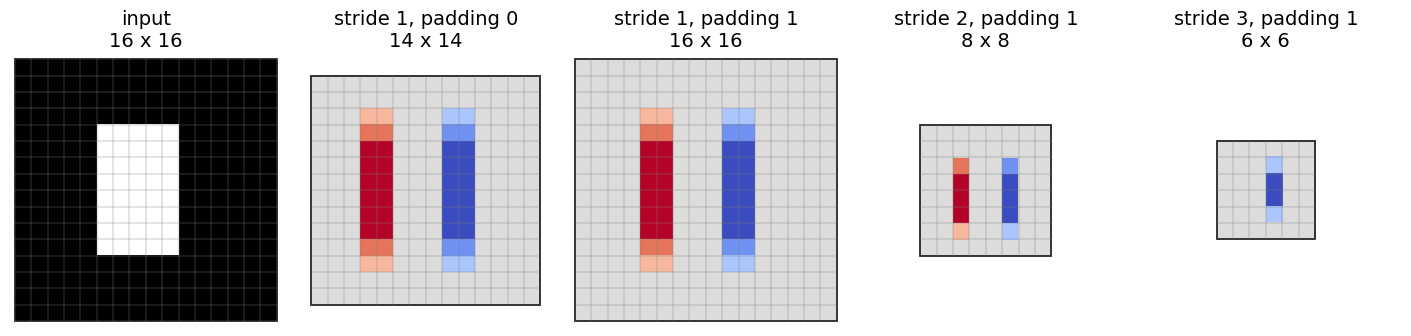

In [40]:
toy_image = torch.zeros(16, 16)
toy_image[4:12, 5:10] = 1.0
scaled_kernel = edge_kernel / 6


def show_same_scale(axis, image, title, **style):
    # every panel covers the same 16 x 16 area, so one pixel has the same size in all of them
    height, width = image.shape
    top, left = (16 - height) / 2, (16 - width) / 2
    axis.imshow(image, extent=(left, left + width, top + height, top), interpolation="nearest", **style)
    # thin lines between the pixels, and an outline around the map
    axis.vlines(np.arange(left, left + width + 1), top, top + height, color="0.5", linewidth=0.3)
    axis.hlines(np.arange(top, top + height + 1), left, left + width, color="0.5", linewidth=0.3)
    axis.add_patch(plt.Rectangle((left, top), width, height, fill=False, edgecolor="black", linewidth=1.2))
    axis.set(xlim=(-0.3, 16.3), ylim=(16.3, -0.3))
    axis.set_title(title, fontsize=14)
    axis.axis("off")


settings = [(1, 0), (1, 1), (2, 1), (3, 1)]  # (stride, padding)
fig, axes = plt.subplots(1, 5, figsize=(14, 3.6), constrained_layout=True)
show_same_scale(axes[0], toy_image, "input\n16 x 16", cmap="gray", vmin=0, vmax=1)
for axis, (stride, padding) in zip(axes[1:], settings):
    your_map = convolve(toy_image, scaled_kernel, stride=stride, padding=padding)
    show_same_scale(
        axis,
        your_map,
        f"stride {stride}, padding {padding}\n{your_map.shape[0]} x {your_map.shape[1]}",
        cmap="coolwarm", vmin=-0.5, vmax=0.5,
    )
plt.show()

## 1.4 What happens when the object moves? 

The 2D convolution (or the cross-correlation) operation respects **translation equivariance**: the output changes position in a predictable way. For stride-one convolution away from image boundaries, if $T_\Delta$ is a translation and $F$ is the convolution,

$$F(T_\Delta x)=T_\Delta F(x).$$

The next two cells show this on the simple shape used above.

The helper `translate_zero_fill` moves an image and fills the newly exposed area with zeros. Positive `dy` moves content down, and positive `dx` moves it right.

In [41]:
def translate_zero_fill(images, dy, dx):
    if images.ndim not in (2, 4):
        raise ValueError("images must have shape [H,W] or [N,C,H,W]")
    if not isinstance(dy, int) or not isinstance(dx, int):
        raise TypeError("dy and dx must be Python integers")

    height, width = images.shape[-2:]
    translated = torch.zeros_like(images)

    if abs(dy) >= height or abs(dx) >= width:
        return translated

    src_y0, src_y1 = max(0, -dy), min(height, height - dy)
    src_x0, src_x1 = max(0, -dx), min(width, width - dx)
    dst_y0, dst_y1 = max(0, dy), min(height, height + dy)
    dst_x0, dst_x1 = max(0, dx), min(width, width + dx)

    translated[..., dst_y0:dst_y1, dst_x0:dst_x1] = images[
        ..., src_y0:src_y1, src_x0:src_x1
    ]

    return translated

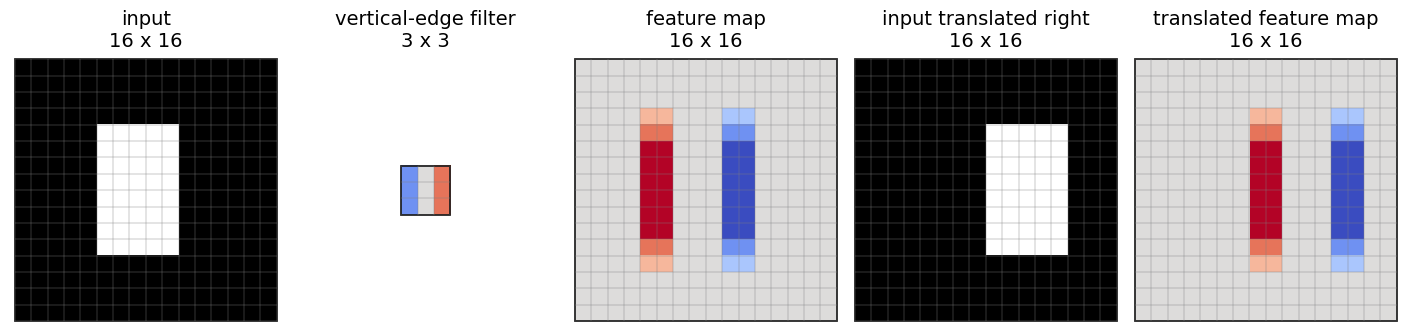

In [42]:
translated_toy = translate_zero_fill(toy_image, dy=0, dx=3)
response = convolve(toy_image, scaled_kernel, stride=1, padding=1)
translated_response = convolve(translated_toy, scaled_kernel, stride=1, padding=1)

response_limit = max(
    response.abs().max().item(),
    translated_response.abs().max().item(),
)

fig, axes = plt.subplots(1, 5, figsize=(14, 3.6), constrained_layout=True)

panels = [
    (toy_image, "input", "gray", 0, 1),
    (scaled_kernel, "vertical-edge filter", "coolwarm", -0.25, 0.25),
    (response, "feature map",
     "coolwarm", -response_limit, response_limit),
    (translated_toy, "input translated right", "gray", 0, 1),
    (translated_response, "translated feature map",
     "coolwarm", -response_limit, response_limit),
]

# same display as in Section 1.3: one pixel has the same size in every panel
for axis, (image, title, cmap, vmin, vmax) in zip(axes, panels):
    show_same_scale(
        axis,
        image,
        f"{title}\n{image.shape[0]} x {image.shape[1]}",
        cmap=cmap, vmin=vmin, vmax=vmax,
    )

plt.show()

expected_response = translate_zero_fill(response, dy=0, dx=3)


# 2. Load A Small CIFAR-10 Dataset

CIFAR-10 contains small RGB images from **ten object classes**. To keep the lab comfortable on a laptop, we use 8,000 images for training and 2,000 for validation.

We first display four original examples so that you can see how small and pixelated the $32\times32$ images are before any preprocessing.

We resize each image to $24\times24$ and place it in the centre of a $32\times32$ mean-colour canvas. This leaves room to translate the image by up to four pixels without cropping the resized content. It is a controlled teaching setup rather than the original CIFAR-10 framing.


In [43]:
# read the fixed subset supplied for the lab
try:
    with np.load(DATA_FILE, allow_pickle=False) as lab_data:
        format_version = int(lab_data["format_version"].item())
        OFFICIAL_TRAIN_SIZE = int(lab_data["official_training_size"].item())
        CLASS_NAMES = lab_data["class_names"].tolist()
        train_images_uint8 = np.array(lab_data["train_images"], copy=True)
        train_labels_numpy = np.array(lab_data["train_labels"], copy=True)
        validation_images_uint8 = np.array(
            lab_data["validation_images"], copy=True
        )
        validation_labels_numpy = np.array(
            lab_data["validation_labels"], copy=True
        )
except (KeyError, OSError, ValueError) as error:
    raise RuntimeError(
        f"{DATA_FILENAME} could not be read. Download a fresh copy from the LMS."
    ) from error

expected_class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

# check shapes, types, and class balance so a wrong file fails before training
valid_schema = (
    format_version == 1
    and CLASS_NAMES == expected_class_names
    and train_images_uint8.shape == (8_000, 32, 32, 3)
    and validation_images_uint8.shape == (2_000, 32, 32, 3)
    and train_labels_numpy.shape == (8_000,)
    and validation_labels_numpy.shape == (2_000,)
    and train_images_uint8.dtype == np.uint8
    and validation_images_uint8.dtype == np.uint8
    and train_labels_numpy.dtype == np.uint8
    and validation_labels_numpy.dtype == np.uint8
    and np.array_equal(
        np.bincount(train_labels_numpy, minlength=10), np.full(10, 800)
    )
    and np.array_equal(
        np.bincount(validation_labels_numpy, minlength=10), np.full(10, 200)
    )
)
if not valid_schema:
    raise RuntimeError(
        f"{DATA_FILENAME} has an unexpected structure. Download a fresh LMS copy."
    )


The file stores the images as arrays of shape `[N, H, W, C]`, with integer values between 0 and 255. PyTorch convolutions expect tensors of shape `[N, C, H, W]` with float values.

---

**Task 5**: In the function `cifar_images_to_tensor` (next cell), complete the two lines `images = ...`: the first reorders the axes from `[N, H, W, C]` to `[N, C, H, W]`, the second turns the integers between 0 and 255 into floats between 0 and 1. 

In [44]:
def cifar_images_to_tensor(numpy_images: np.ndarray) -> torch.Tensor:
    """
    Converts a batch of images to the layout expected by PyTorch
    input:
        numpy_images (np.ndarray): (N, H, W, C) integers between 0 and 255

    returns:
        images (torch.Tensor): (N, C, H, W) floats between 0 and 1
    """
    images = torch.from_numpy(numpy_images)
    images =  images.permute(0, 3, 1, 2) #> YOUR CODE HERE: reorder the axes from [N, H, W, C] to [N, C, H, W]
    images =  images / 255 #> YOUR CODE HERE: floats between 0 and 1 instead of integers between 0 and 255
    return images


x_train_raw = cifar_images_to_tensor(train_images_uint8)
y_train = torch.from_numpy(train_labels_numpy.astype(np.int64))
x_val_raw = cifar_images_to_tensor(validation_images_uint8)
y_val = torch.from_numpy(validation_labels_numpy.astype(np.int64))

print("training images:  ", tuple(x_train_raw.shape), x_train_raw.dtype)
print("validation images:", tuple(x_val_raw.shape), x_val_raw.dtype)
print("values from", x_train_raw.min().item(), "to", x_train_raw.max().item())


training images:   (8000, 3, 32, 32) torch.float32
validation images: (2000, 3, 32, 32) torch.float32
values from 0.0 to 1.0


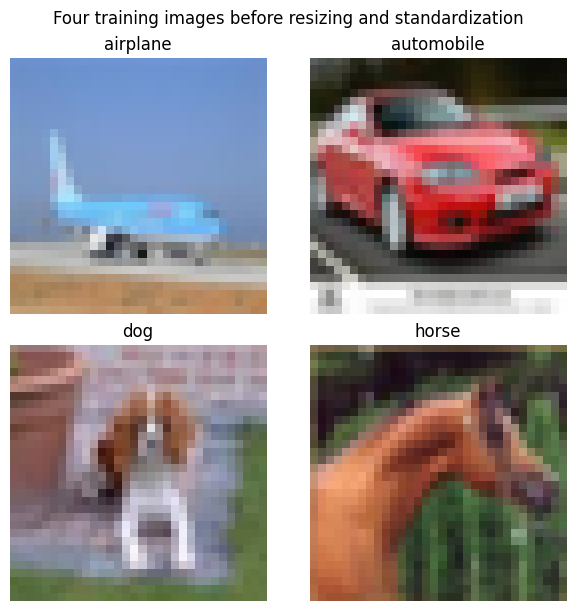

In [45]:
preview_class_ids = (0, 1, 5, 7)  # airplane, automobile, dog, horse
preview_indices = [
    int(torch.where(y_train == class_id)[0][0])
    for class_id in preview_class_ids
]
preview_images = x_train_raw[preview_indices].clone()
preview_labels = y_train[preview_indices].clone()

fig, axes = plt.subplots(2, 2, figsize=(6, 6), constrained_layout=True)
for axis, image, label in zip(axes.flat, preview_images, preview_labels):
    axis.imshow(image.permute(1, 2, 0), interpolation="nearest")
    axis.set_title(CLASS_NAMES[label.item()])
    axis.axis("off")

fig.suptitle("Four training images before resizing and standardization")
plt.show()


We finish the preprocessing of raw images with two more steps:

- estimate channel-wise mean and standard deviation using only the training set, then normalize images;
- randomly translate training images by up to four pixels, but keep validation images centred for consistent evaluation

The random translations help the CNN learn predictions that are less sensitive to the exact position of an object.

In [46]:
# estimate normalization statistics from the training split only
channel_mean = x_train_raw.mean(dim=(0, 2, 3))
channel_std = x_train_raw.std(dim=(0, 2, 3), unbiased=False)


def normalize_images(images):
    return (images - channel_mean[None, :, None, None]) / channel_std[None, :, None, None]


def denormalize_images(images):
    return images * channel_std[None, :, None, None] + channel_mean[None, :, None, None]


def place_on_mean_canvas(raw_images):
    # shrinking to 24 x 24 leaves room to translate the object inside a 32 x 32 canvas
    normalized = normalize_images(raw_images)
    resized = F.interpolate(
        normalized,
        size=(24, 24),
        mode="bilinear",
        align_corners=False,
        antialias=True,
    )
    # zero represents the training-set mean colour after normalization
    canvas = torch.zeros(len(raw_images), 3, 32, 32, dtype=resized.dtype)
    canvas[:, :, 4:28, 4:28] = resized
    return canvas


x_train_canonical = place_on_mean_canvas(x_train_raw)
x_val_canonical = place_on_mean_canvas(x_val_raw)

translated_probe = translate_zero_fill(x_val_canonical[:4], 4, -4)
assert torch.equal(
    translated_probe[:, :, 8:32, 0:24],
    x_val_canonical[:4, :, 4:28, 4:28],
)
assert torch.equal(torch.bincount(y_train, minlength=10), torch.full((10,), 800))
assert torch.equal(torch.bincount(y_val, minlength=10), torch.full((10,), 200))
print("Official CIFAR-10 training data:", OFFICIAL_TRAIN_SIZE)
print("Lab train / validation: 8000 / 2000 (official test set not used)")


class RandomTranslationCIFAR(Dataset):
    # return the image at a fresh random canvas position on each access.

    def __init__(self, canonical_images, targets, max_translation=4):
        self.canonical_images = canonical_images
        self.targets = targets
        self.max_translation = int(max_translation)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        dy, dx = torch.randint(
            -self.max_translation,
            self.max_translation + 1,
            size=(2,),
        ).tolist()
        image = translate_zero_fill(
            self.canonical_images[index:index + 1],
            dy=int(dy),
            dx=int(dx),
        )[0]
        return image, self.targets[index]


augmented_train_dataset = RandomTranslationCIFAR(
    x_train_canonical, y_train, max_translation=4
)
canonical_val_dataset = TensorDataset(x_val_canonical, y_val)

BATCH_SIZE = 256


def make_loader(dataset, shuffle, seed):
    # the seeded generator controls the shuffled minibatch order
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator,
        num_workers=0,
    )


Official CIFAR-10 training data: 50000
Lab train / validation: 8000 / 2000 (official test set not used)


# 3. From Convolution to a CNN

A CNN classifier usually has two parts:

$$
\text{image}
\longrightarrow \underbrace{\text{Convolutions + ReLU + Max Pooling}}_{\text{feature extractor}}
\longrightarrow \underbrace{\text{Global Average Pooling + small MLP}}_{\text{classification head}}
\longrightarrow \text{class scores}
$$

<img src="https://commons.wikimedia.org/wiki/Special:Redirect/file/Typical_cnn.png"
     alt="Pipeline of a typical convolutional neural network"
     width="800"/>

## 3.1 Convolutions

The convolution operation produces feature maps using learned local, shared filters. 

In Section 1, we applied a single convolution kernel by hand. PyTorch provides it as a layer, [`nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), which replaces our hand-crafted `convolve`. It takes the same concepts of kernel size, stride and padding, but with three important extensions: 

- It works on a **batch** of images with several **channels**, of shape `[B, C, H, W]`;
- We no longer choose the values of the kernels by ourselves. They are now parameters of the layer, **learned during training**; 
- We can have **multiple learnable filters operating in parallel**. Each filter produces one output feature map, so a convolution layer with $k$ filters produces $k$ feature maps for each image. 

The layer is created with `nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0, bias=True)`:

| parameter | meaning | in our CNN |
|---|---|---|
| `in_channels` | number of channels of the input tensor: 3 for an RGB image, or the number of feature maps produced by the previous layer | 3, 16, 32 |
| `out_channels` | number of kernels of the layer, which is also the number of feature maps it produces | 16, 32, 64 |
| `kernel_size` | height and width of each kernel, as in Section 1.3 | 3 |
| `stride` | how far the kernels move at each step, as in Section 1.3; 1 by default | 1 |
| `padding` | number of rows and columns of zeros added on each side of the input, as in Section 1.3; 0 by default | 1 |
| `bias` | whether one learned constant per kernel is added to its feature map; `True` by default | `True` |

The learned parameters of the layer are its kernels, stored in a weight tensor of shape `[out_channels, in_channels, kernel_size, kernel_size]`, and one bias per kernel. An input of shape `[B, in_channels, H, W]` gives an output of shape `[B, out_channels, H', W']`, where $H'$ and $W'$ follow the formula of Section 1.3.

For example, `nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)` takes an input with 3 channels `[B, C=3, H, W]` and applies 16 different convolutional filters. Each filter spans all 3 input channels and therefore has shape $3\times 3\times 3$. Each filter produces one two-dimensional feature map, giving 16 output feature maps in total `[B, C'=16, H', W']`. 

We also no longer choose the values inside these filters ourselves. They are parameters of the layer and are learned during training through backpropagation. We previously chose an edge-detection filter by hand only to make its behavior predictable. In a real CNN, different filters learn to respond to different patterns that help reduce the classification loss. Early filters often respond to edges, colors, or simple textures, while deeper layers combine these responses into increasingly task-relevant features.

For an RGB image, each filter therefore contains three slices—one for the red channel, one for green, and one for blue. The three convolution results are summed to produce one feature map. Having many such filters in parallel allows the convolutional layer to detect many different learned patterns at the same spatial locations.

## 3.2 Max pooling

The max pooling keeps the largest value in each small window and reduces spatial size. For example, `MaxPool2d(2)` keeps the largest activation in each $2\times2$ region of each feature map: 

$$
\operatorname{max}
\begin{bmatrix}
0.1 & 0.8\\
0.4 & 0.2
\end{bmatrix}
=0.8
$$

Why do we need it? A convolution with stride 1 and padding 1 keeps the height and width of its input, so without pooling every layer would work on full-size feature maps. Max pooling is placed between the convolutions for three reasons:

- **Less computation.** Each $2\times2$ pooling halves the height and the width, so the following layers process 4 times fewer values.
- **A larger field of view.** After one pooling, a $3\times3$ kernel covers a region twice as wide in the original image. By alternating convolutions and poolings, deeper layers combine information over larger and larger parts of the image while keeping small kernels.
- **Tolerance to small shifts.** The maximum of a window does not change when a feature moves inside this window, so the output changes less when the object moves by a pixel or two. For classification, *whether* a feature is present matters more than its exact position.

The price is that max pooling discards the other values and the exact position of the maximum. This can help classification after useful local features have been detected, but early or aggressive pooling can hurt tasks that need precise locations. It can reduce position sensitivity, but does not guarantee translation invariance.

## 3.3 Global average pooling

After several convolutional layers, each image is represented by a collection of two-dimensional feature maps. To perform classification, we will use a lightweight multilayer perceptron (MLP), similar to the classifiers introduced in the previous two labs. Since an MLP typically expects a one-dimensional feature vector for each input sample, the convolutional feature maps must first be converted into a fixed-length vector representation.

We apply a global average pooling in this case to convert a stack of feature maps into a single feature vector, so that each of the final feature maps contributes exactly one number: 

$$
\frac{1}{H'W'}
\sum_{i=1}^{H'}
\sum_{j=1}^{W'}
F_k(i,j)
$$

Intuitively, instead of asking where a feature occurred, global average pooling summarizes how strongly that feature was present across the image.

This also makes the classifier independent of the exact spatial dimensions of the final feature maps.

Global average pooling is only one option among several. For final feature maps of shape `[B, 64, 8, 8]`, common choices are:

| option | feature vector | what it keeps | drawback |
|---|---|---|---|
| **flatten**, as in the figure above | $64\times8\times8=4096$ values | every value, with its position | the first linear layer needs many weights, and the image size is fixed |
| **global max pooling** | 64 values | the strongest response of each feature map: is the feature present anywhere? | ignores how much of the image shows the feature |
| **global average pooling**, our choice | 64 values | the average response of each feature map | the positions are lost |

We choose global average pooling here because it keeps the classifier small and accepts images of any size. It is not always the best choice: when the position of a feature matters for the task, flattening can work better.


# 4. Our CNN

Now let's design our CNN with following operations in a sequence: 

1. Convolve with 16 kernels, each of kernel size 3, followed by ReLU activation function; 

2. Max pool with kernel size 2 and stride 2; 

3. Convolve with 32 kernels, each of kernel size 3, followed by ReLU activation function; 

4. Max pool with kernel size 2 and stride 2; 

5. Convolve with 64 kernels, each of kernel size 3, followed by ReLU activation function; 

6. Global average pool over the two spatial dimensions to obtain a `[B, 64]` feature vector; 

7. Pass the vector through `Linear(64, 32)` $\rightarrow$ ReLU $\rightarrow$ `Linear(32, 10)` to obtain **logits** over 10 classes. 

---

**Task 6**: Complete the class `CNN` (next cell) so that it applies the seven operations listed just above. In `__init__`, create the layers under these exact names, which the rest of the notebook uses: `self.conv_layer1`, `self.conv_layer2` and `self.conv_layer3` for the three convolutions, `self.pool` for the max pooling, and `self.classifier` for the head of operation 7. Give every convolution the kernel size, stride and padding of the table in Section 1.3. In `forward_feature_extractor`, complete the four lines `conv1 = ...`, `conv2 = ...`, `conv3 = ...` and `feature_vector = ...`: each `conv` variable is the output of one convolution after its ReLU and before the next max pooling, and `feature_vector` is the result of operation 6, of shape `[B, 64]`. 

In [47]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        #> YOUR CODE HERE: define the three convolutions self.conv_layer1, self.conv_layer2, self.conv_layer3 and the max pooling self.pool
        self.conv_layer1 = nn.Conv2d(3, 16, 3, 1, 1, bias=True)
        self.conv_layer2 = nn.Conv2d(16, 32, 3, 1, 1, bias=True)
        self.conv_layer3 = nn.Conv2d(32, 64, 3, 1, 1, bias=True)

        self.pool = nn.MaxPool2d(2, 2)

        #> YOUR CODE HERE: define self.classifier, the small MLP that turns the 64 features into 10 logits
        self.relu = nn.ReLU()
        self.classifier = nn.Sequential(
            nn.Linear(64, 32),
            self.relu,
            nn.Linear(32, 10),
        )




    def forward_feature_extractor(self, x):
        conv1 =  self.relu(self.conv_layer1(x)) #> YOUR CODE HERE: feature maps after the first convolution and ReLU
        conv2 =  self.relu(self.conv_layer2(self.pool(conv1))) #> YOUR CODE HERE: feature maps after pooling conv1, the second convolution and ReLU
        conv3 =  self.relu(self.conv_layer3(self.pool(conv2))) #> YOUR CODE HERE: feature maps after pooling conv2, the third convolution and ReLU
        feature_vector = torch.mean(conv3, dim=(2, 3)) #> YOUR CODE HERE: global average pooling of conv3, of shape [B, 64]
        
        # here we cache the feature maps for visualization, but they are not used for classification
        feature_maps = {"conv1": conv1, "conv2": conv2, "conv3": conv3}
        return feature_vector, feature_maps

    def forward(self, x):
        feature_vector, _ = self.forward_feature_extractor(x)
        logits = self.classifier(feature_vector)
        return logits


In [48]:
def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


# check the model interface and tensor shapes before spending time on training
torch.manual_seed(SEED + 100)
cnn_probe = CNN()
probe_batch = torch.randn(5, 3, 32, 32)
probe_vector, probe_maps = cnn_probe.forward_feature_extractor(probe_batch)
probe_logits = cnn_probe(probe_batch)

expected_shapes = {
    "conv1": (5, 16, 32, 32),
    "conv2": (5, 32, 16, 16),
    "conv3": (5, 64, 8, 8),
}
actual_shapes = {name: tuple(value.shape) for name, value in probe_maps.items()}

# shapes of the tensors that flow through the network for a batch of 5 images (not of the kernels)
probe_tensors = {
    "input images": (probe_batch, (5, 3, 32, 32)),
    "feature maps after conv1 + ReLU": (probe_maps["conv1"], expected_shapes["conv1"]),
    "feature maps after conv2 + ReLU": (probe_maps["conv2"], expected_shapes["conv2"]),
    "feature maps after conv3 + ReLU": (probe_maps["conv3"], expected_shapes["conv3"]),
    "feature vector (one value per feature map)": (probe_vector, (5, 64)),
    "logits (one score per class)": (probe_logits, (5, 10)),
}
shape_table = pd.DataFrame(
    [
        {
            "tensor": name,
            "B": tensor.shape[0],
            "C": tensor.shape[1],
            "H": tensor.shape[2] if tensor.ndim == 4 else "-",
            "W": tensor.shape[3] if tensor.ndim == 4 else "-",
            "your shape": str(tuple(tensor.shape)),
            "expected": str(expected),
        }
        for name, (tensor, expected) in probe_tensors.items()
    ]
).set_index("tensor")
display(shape_table)
print("Each row is the shape [B, C, H, W] of a tensor flowing through the network: B images, each with C channels of H x W values.")
print("After a convolution, the C channels are the feature maps: one per kernel of that layer.")
print(
    "These are not the shapes of the kernels. The kernels of conv1, for example, have shape",
    tuple(cnn_probe.conv_layer1.weight.shape),
    "= [out_channels, in_channels, k, k].",
)

assert actual_shapes == expected_shapes
assert probe_vector.shape == (5, 64)
assert probe_logits.shape == (5, 10)
# spatial averaging keeps the classifier input at 64 values for a larger image too
larger_probe_logits = cnn_probe(torch.randn(2, 3, 40, 40))
assert larger_probe_logits.shape == (2, 10)
assert all(feature_map.min().item() >= 0 for feature_map in probe_maps.values())
assert torch.allclose(probe_logits, cnn_probe.classifier(probe_vector))
assert count_parameters(cnn_probe) == 25_994
print(cnn_probe)
print("CNN checks passed. Trainable parameters:", count_parameters(cnn_probe))
print("A 40 x 40 batch also produces logits with shape:", tuple(larger_probe_logits.shape))


,B,C,H,W,your shape,expected
tensor,,,,,,
input images,5,3,32,32,"(5, 3, 32, 32)","(5, 3, 32, 32)"
feature maps after conv1 + ReLU,5,16,32,32,"(5, 16, 32, 32)","(5, 16, 32, 32)"
feature maps after conv2 + ReLU,5,32,16,16,"(5, 32, 16, 16)","(5, 32, 16, 16)"
feature maps after conv3 + ReLU,5,64,8,8,"(5, 64, 8, 8)","(5, 64, 8, 8)"
feature vector (one value per feature map),5,64,-,-,"(5, 64)","(5, 64)"
logits (one score per class),5,10,-,-,"(5, 10)","(5, 10)"


Each row is the shape [B, C, H, W] of a tensor flowing through the network: B images, each with C channels of H x W values.
After a convolution, the C channels are the feature maps: one per kernel of that layer.
These are not the shapes of the kernels. The kernels of conv1, for example, have shape (16, 3, 3, 3) = [out_channels, in_channels, k, k].
CNN(
  (conv_layer1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_layer2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_layer3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=10, bias=True)
  )
)
CNN checks passed. Trainable parameters: 25994
A 40 x 40 batch also produces logits with shape: (2, 10)


# 5. A Baseline: the Single MLP

To judge what the convolutions bring, we compare the CNN with a multilayer perceptron (MLP) like the one of Lab 2. An MLP first flattens the image. Its dense units use different weights for different input coordinates, so it has no built-in notion that nearby pixels belong together.


In [49]:
class SingleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 8),
            nn.ReLU(),
            nn.Linear(8, 10),
        )

    def forward(self, x):
        return self.network(x)


In [50]:
mlp_probe = SingleMLP()
assert mlp_probe(torch.randn(3, 3, 32, 32)).shape == (3, 10)

comparison = pd.DataFrame(
    {
        "trainable parameters": [
            count_parameters(mlp_probe),
            count_parameters(cnn_probe),
        ],
        "keeps a spatial grid": [False, True],
        "reuses local filters": [False, True],
        "same head accepts 40 x 40": [False, True],
    },
    index=["MLP", "CNN"],
)
display(comparison)
print(
    "The parameter counts are similar, but the connectivity is very different. "
)

,trainable parameters,keeps a spatial grid,reuses local filters,same head accepts 40 x 40
MLP,24674,False,False,False
CNN,25994,True,True,True


The parameter counts are similar, but the connectivity is very different. 


## 6. Train An MLP and A CNN

We now train these two models in parallel: one single MLP and one CNN. Both see the same randomly translated training images and are evaluated on the same validation data. This keeps the focus on the architectural difference—dense coordinate-specific connections versus local, shared filters—without adding a separate augmentation experiment.

**Before running the cell:** which model do you expect to learn faster, and which do you expect to be less sensitive to the object's position? Give one reason for each prediction.

**Answer:**
    - I expect the MLP to be faster since it does less computations
    - I expect the MLP to be sensative to the object position since it flattens totally inputs before starting, thus loses the 2D comprehension 

---

**Task 7**: In the function `train_one_epoch` (next cell), write the training step of one minibatch: clear the gradients of `optimizer`, compute `logits`, compute the cross-entropy `loss`, run the backward pass, and update the parameters. Keep the names `logits` and `loss`: the lines that follow are already written and use them. 


In [51]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    criterion = nn.CrossEntropyLoss()
    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        
        #> YOUR CODE HERE: the training step for this minibatch (5 lines); it must define `logits` and `loss`
        logits = model(inputs)
        loss = criterion(logits, targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # weight by batch size because the final minibatch may be smaller
        batch_size = targets.shape[0]
        batch_correct = (logits.argmax(dim=1) == targets).sum().item()  # number of correct predictions in this minibatch
        total_loss += loss.item() * batch_size
        total_correct += batch_correct
        total_examples += batch_size

    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
    }

In [52]:
# evaluation needs no gradient graph, which saves memory and computation
@torch.inference_mode()
def evaluate(model, loader, keep_outputs=False):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    all_logits, all_targets = [], []

    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        logits = model(inputs)
        loss = F.cross_entropy(logits, targets)
        predictions = logits.argmax(dim=1)
        batch_size = targets.shape[0]
        total_loss += loss.item() * batch_size
        total_correct += (predictions == targets).sum().item()
        total_examples += batch_size
        if keep_outputs:
            all_logits.append(logits.cpu())
            all_targets.append(targets.cpu())

    result = {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
    }
    if keep_outputs:
        result["logits"] = torch.cat(all_logits)
        result["targets"] = torch.cat(all_targets)
    return result


def fit_model(model, train_dataset, *, run_seed, epochs=30, learning_rate=0.001):
    # resetting this seed means both deterministic models receive the same minibatch order 
    # and the same sequence of random translations
    torch.manual_seed(run_seed)
    train_loader = make_loader(train_dataset, shuffle=True, seed=run_seed + 1)
    val_loader = make_loader(canonical_val_dataset, shuffle=False, seed=0)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # keep the checkpoint with the lowest validation loss, not simply the final epoch
    best_val_loss = float("inf")
    best_epoch = None
    best_state = None
    history = []

    start = time.time()
    for epoch in range(1, epochs + 1):
        train_metrics = train_one_epoch(model, train_loader, optimizer)
        val_metrics = evaluate(model, val_loader)
        history.append(
            {
                "epoch": epoch,
                "train loss": train_metrics["loss"],
                "train accuracy": train_metrics["accuracy"],
                "val loss": val_metrics["loss"],
                "val accuracy": val_metrics["accuracy"],
            }
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    selected_validation = evaluate(model, val_loader)
    print(f"Training finished for {model.__class__.__name__} in {time.time() - start:.1f} seconds")
    
    return {
        "model": model,
        "history": pd.DataFrame(history),
        "best epoch": best_epoch,
        "val loss": selected_validation["loss"],
        "val accuracy": selected_validation["accuracy"],
    }


In [ ]:
torch.manual_seed(SEED + 200)
mlp_model = SingleMLP().to(DEVICE)

torch.manual_seed(SEED + 300)
cnn_model = CNN().to(DEVICE)

experiment_runs = {
    "MLP": fit_model(
        mlp_model,
        augmented_train_dataset,
        run_seed=SEED + 500,
    ),
    "CNN": fit_model(
        cnn_model,
        augmented_train_dataset,
        run_seed=SEED + 500,
    ),
}

validation_summary = pd.DataFrame(
    [
        {
            "model": name,
            "parameters": count_parameters(run["model"]),
            "selected epoch": run["best epoch"],
            "validation loss": run["val loss"],
            "validation accuracy": run["val accuracy"],
        }
        for name, run in experiment_runs.items()
    ]
)

display(
    validation_summary.style.hide(axis="index").format(
        {"validation loss": "{:.3f}", "validation accuracy": "{:.3f}"}
    )
)


Training finished for SingleMLP in 13.6 seconds


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
colours = {"MLP": "tab:orange", "CNN": "tab:blue"}

for name, run in experiment_runs.items():
    history = run["history"]
    colour = colours[name]
    axes[0].plot(history["epoch"], history["val loss"], label=name, color=colour)
    axes[1].plot(
        history["epoch"], history["val accuracy"], label=name, color=colour
    )
    # The dot marks the checkpoint restored after training.
    best = run["best epoch"] - 1
    axes[0].scatter(
        history["epoch"].iloc[best], history["val loss"].iloc[best],
        color=colour, s=35,
    )
    axes[1].scatter(
        history["epoch"].iloc[best], history["val accuracy"].iloc[best],
        color=colour, s=35,
    )

axes[0].set(title="Validation loss", xlabel="epoch", ylabel="cross-entropy loss")
axes[1].set(title="Validation accuracy", xlabel="epoch", ylabel="accuracy")
axes[1].set_ylim(0, 1.0)
axes[1].axhline(0.10, color="0.45", linestyle=":", label="chance")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
plt.show()


# 7. Inspect What the Models Learned

We use three displays, each answering a different question:

1. **Translation-accuracy grid:** how stable is the model's accuracy when every validation image is translated by the same offset? Each square is the accuracy over the complete 2,000-image validation set at one translation. The centre square is no translation.

2. **Kernels:** what does each learned kernel look for in an image?

3. **Grad-CAM:** which regions provide positive support for one chosen class score?

## 7.1 Translation-invariance of CNN

In the first figure, the example images above the grids make the translation directions concrete. The horizontal axis is `dx` (left/right) and the vertical axis is `dy` (up/down), both in pixels. The MLP and CNN grids share one colour scale, so their colours are comparable. Below each accuracy, the number in brackets is its difference from the centre square: the accuracy lost or gained because of the translation.

In [ ]:
# supplied helper: evaluate the same images at several translations
def accuracy_by_translation(model, canonical_images, labels, translations, batch_size=256):
    was_training = model.training
    model.eval()

    try:
        results = {}
        with torch.inference_mode():
            for dy, dx in translations:
                translated = (
                    canonical_images
                    if (dy, dx) == (0, 0)
                    else translate_zero_fill(canonical_images, int(dy), int(dx))
                )
                # process the translated validation set in manageable minibatches
                predictions = []
                for start in range(0, len(translated), batch_size):
                    logits = model(
                        translated[start:start + batch_size].to(DEVICE)
                    )
                    predictions.append(logits.argmax(dim=1).cpu())
                predictions = torch.cat(predictions)
                results[(int(dy), int(dx))] = (
                    predictions == labels
                ).float().mean().item()
        return results
    finally:
        # return the model to the mode it had before this diagnostic
        model.train(was_training)


In [ ]:
TRANSLATION_VALUES = (-4, 0, 4)
TRANSLATION_GRID = [
    (dy, dx)
    for dy in TRANSLATION_VALUES
    for dx in TRANSLATION_VALUES
]
translation_results = {
    name: accuracy_by_translation(
        run["model"], x_val_canonical, y_val, TRANSLATION_GRID
    )
    for name, run in experiment_runs.items()
}

selected_cnn = experiment_runs["CNN"]["model"]
print("Calculated nine validation accuracies for each model.")


In [ ]:
def make_accuracy_grid(results):
    return np.array(
        [
            [results[(dy, dx)] for dx in TRANSLATION_VALUES]
            for dy in TRANSLATION_VALUES
        ]
    )


all_accuracies = [
    accuracy
    for results in translation_results.values()
    for accuracy in results.values()
]
colour_min = max(0.0, min(all_accuracies) - 0.03)
colour_max = min(1.0, max(all_accuracies) + 0.03)
if colour_max - colour_min < 0.10:
    midpoint = 0.5 * (colour_min + colour_max)
    colour_min = max(0.0, midpoint - 0.05)
    colour_max = min(1.0, midpoint + 0.05)

fig = plt.figure(figsize=(12, 6.4), constrained_layout=True)
layout = fig.add_gridspec(2, 3, height_ratios=[0.8, 1.2])

# the top row makes the sign and direction of (dy, dx) concrete
example_index = 0
example_translations = [(-4, -4), (0, 0), (4, 4)]
example_titles = [
    "translate up and left\n(dy=-4, dx=-4)",
    "no translation\n(dy=0, dx=0)",
    "translate down and right\n(dy=4, dx=4)",
]
for column, ((dy, dx), title) in enumerate(
    zip(example_translations, example_titles)
):
    axis = fig.add_subplot(layout[0, column])
    image = translate_zero_fill(
        x_val_canonical[example_index:example_index + 1], dy, dx
    )
    rgb = denormalize_images(image)[0].permute(1, 2, 0).clamp(0, 1)
    axis.imshow(rgb)
    axis.set_title(title, fontsize=10)
    axis.axis("off")

# the bottom row uses a shared colour scale so the two models can be compared
summary_rows = []
heatmap_axes = []
heatmap_artist = None
for column, (name, results) in enumerate(translation_results.items()):
    axis = fig.add_subplot(layout[1, column])
    heatmap_axes.append(axis)
    grid = make_accuracy_grid(results)
    heatmap_artist = axis.imshow(
        grid,
        cmap="viridis",
        vmin=colour_min,
        vmax=colour_max,
    )
    centre = results[(0, 0)]
    for row in range(3):
        for grid_column in range(3):
            value = grid[row, grid_column]
            relative = (value - colour_min) / max(colour_max - colour_min, 1e-12)
            # below each accuracy: its difference from the centre square (no translation)
            label = f"{value:.3f}"
            if (row, grid_column) != (1, 1):
                label += f"\n({value - centre:+.3f})"
            axis.text(
                grid_column,
                row,
                label,
                ha="center",
                va="center",
                color="white" if relative < 0.55 else "black",
                fontweight="bold",
            )
    axis.set_xticks(range(3), labels=TRANSLATION_VALUES)
    axis.set_yticks(range(3), labels=TRANSLATION_VALUES)
    axis.set_xlabel("horizontal translation dx (pixels)")
    axis.set_ylabel("vertical translation dy (pixels)")
    axis.set_title(name)

    translated_values = [
        value for translation, value in results.items() if translation != (0, 0)
    ]
    summary_rows.append(
        {
            "model": name,
            "no translation": results[(0, 0)],
            "mean of 8 translations": float(np.mean(translated_values)),
            "worst translation": float(np.min(translated_values)),
        }
    )

explanation_axis = fig.add_subplot(layout[1, 2])
explanation_axis.axis("off")
explanation_axis.text(
    0.02,
    0.95,
    "How to read one square",
    ha="left",
    va="top",
    fontsize=11,
    fontweight="bold",
    color="#172033",
)
explanation_axis.text(
    0.02,
    0.82,
    "Translate all 2,000 validation images\nby the displayed (dy, dx), then\nmeasure the model's accuracy.\n\nIn brackets: the difference from the\ncentre square (no translation), that is,\nthe accuracy lost or gained because\nof the translation.\n\nA flatter grid means less sensitivity\nto where the object appears.",
    ha="left",
    va="top",
    fontsize=10,
    linespacing=1.35,
    color="#172033",
)
colourbar = fig.colorbar(heatmap_artist, ax=heatmap_axes, shrink=0.86)
colourbar.set_label("validation accuracy")
fig.suptitle(
    f"Translations of one example and accuracy over the full validation set\n"
    f"example class: {CLASS_NAMES[y_val[example_index].item()]}",
    fontsize=13,
)
plt.show()

translation_summary = pd.DataFrame(summary_rows).set_index("model")
display(translation_summary.style.format("{:.3f}"))


## 7.2 What do the kernels look for?

A kernel is only a small grid of numbers. The top row of the next figure shows the 16 kernels of the first layer. Each has shape $3\times3\times3$, with one $3\times3$ grid per colour. They are shown averaged over the three colours, with the colours of Section 1: red for a positive weight, blue for a negative one. The kernel closest to our hand-made vertical-edge kernel $K$, or to its opposite $-K$, is marked.

The kernels of the deeper layers have 16 or 32 input channels and cannot be drawn in this way. A more telling way to look at any kernel is to ask **which image patches give it the largest response**. A unit of `conv1` sees a $3\times3$ patch of the image. Because of the two max poolings, a unit of `conv2` sees an $8\times8$ patch and a unit of `conv3` an $18\times18$ patch. For four kernels of each layer, those with the strongest responses, the figure shows the eight validation patches that excite them most.

Read the figure layer by layer: what do the eight patches of one kernel have in common? Kernels of the first layer typically respond to a colour, to brightness, or to an edge with one orientation, while deeper kernels respond to larger and more specific patterns. If you train on a GPU, your kernels will differ from your neighbours', because training is then not exactly reproducible.

**Answer :** The 8 patches of a kernel are very similar, showing a kind of same pattern

In [ ]:
# predictions of the selected CNN on the validation set (also used for Grad-CAM in Section 7.3)
selected_cnn.eval()
validation_outputs = evaluate(
    selected_cnn,
    make_loader(canonical_val_dataset, shuffle=False, seed=0),
    keep_outputs=True,
)
validation_probabilities = validation_outputs["logits"].softmax(dim=1)
validation_confidence, validation_predictions = validation_probabilities.max(dim=1)

# part of the image seen by one unit of each layer: (first pixel relative to the unit, size, step between units)
RECEPTIVE_FIELDS = {"conv1": (-1, 3, 1), "conv2": (-3, 8, 2), "conv3": (-7, 18, 4)}

# feature maps of all the validation images, moved back to the CPU
with torch.inference_mode():
    batches = [
        selected_cnn.forward_feature_extractor(x_val_canonical[start:start + 500].to(DEVICE))[1]
        for start in range(0, len(x_val_canonical), 500)
    ]
all_maps = {layer: torch.cat([batch[layer].cpu() for batch in batches]) for layer in RECEPTIVE_FIELDS}
validation_rgb = denormalize_images(x_val_canonical).clamp(0, 1)


def strongest_patches(layer, kernels=4, count=8):
    # for the `kernels` kernels with the strongest responses, the `count` image patches that excite them most
    offset, size, step = RECEPTIVE_FIELDS[layer]
    side = all_maps[layer].shape[-1]
    # keep the units whose patch lies inside the 24 x 24 image, away from the canvas border
    units = [u for u in range(side) if u * step + offset >= 4 and u * step + offset + size <= 28]
    maps = all_maps[layer][:, :, units][:, :, :, units]
    # strongest response of every kernel in every image, and where it occurs
    best_value, best_unit = maps.flatten(2).max(dim=2)
    top_value, top_image = best_value.topk(count, dim=0)
    chosen = top_value.mean(dim=0).topk(kernels).indices.tolist()
    patches = {}
    for kernel in chosen:
        patches[kernel] = []
        for image in top_image[:, kernel].tolist():
            row, column = divmod(int(best_unit[image, kernel]), len(units))
            top, left = units[row] * step + offset, units[column] * step + offset
            patches[kernel].append(validation_rgb[image, :, top:top + size, left:left + size])
    return patches


fig = plt.figure(figsize=(13, 10.6), constrained_layout=True)
parts = fig.subfigures(4, 1, height_ratios=[0.66, 1, 1, 1])

# top strip: the kernels of the first layer themselves, with the colours of Section 1
first_kernels = selected_cnn.conv_layer1.weight.detach().cpu().mean(dim=1)
similarity = F.cosine_similarity(first_kernels.flatten(1), edge_kernel.flatten()[None], dim=1)
closest = int(similarity.abs().argmax())
limit = first_kernels.abs().max().item()
parts[0].suptitle(
    "The 16 kernels of conv1, averaged over the three colours (red: positive weight, blue: negative weight)",
    fontsize=11,
)
for kernel, axis in enumerate(parts[0].subplots(1, 16)):
    axis.imshow(first_kernels[kernel], cmap="coolwarm", vmin=-limit, vmax=limit, interpolation="nearest")
    mark = f"\nclosest to {'K' if similarity[kernel] > 0 else '-K'}" if kernel == closest else "\n"
    axis.set_title(f"kernel {kernel}{mark}", fontsize=8)
    axis.set_xticks([])
    axis.set_yticks([])

# three blocks: the image patches that excite four kernels of each layer most
for part, layer in zip(parts[1:], RECEPTIVE_FIELDS):
    size = RECEPTIVE_FIELDS[layer][1]
    part.suptitle(f"{layer}: one unit sees a {size} x {size} patch of the image", fontsize=11)
    axes = part.subplots(2, 17, width_ratios=[1] * 8 + [0.35] + [1] * 8)
    for axis in axes.flat:
        axis.set_xticks([])
        axis.set_yticks([])
    for axis in axes[:, 8]:
        axis.axis("off")
    for group, (kernel, patches) in enumerate(strongest_patches(layer).items()):
        row, half = divmod(group, 2)
        for position, patch in enumerate(patches):
            axis = axes[row, 9 * half + position]
            axis.imshow(patch.permute(1, 2, 0), interpolation="nearest")
            if position == 0:
                axis.set_title(f"kernel {kernel}", fontsize=9, loc="left")

fig.suptitle(
    "What does each kernel look for? The eight validation patches that give its largest responses",
    fontsize=13,
)
plt.show()
print(
    f"Kernel {closest} of conv1 is the closest to our hand-made kernel K of Section 1."
)

## 7.3 Grad-CAM: which regions provide positive support for this class score?

The patches above show what individual kernels look for. Grad-CAM asks a different,
prediction-specific question: which locations in the final feature maps provide positive
support for a chosen class score?

For class score $z_c$ and final feature maps $A^k$, it averages the gradients over space and
uses them as channel weights:

$$
\alpha_k^c=\frac{1}{HW}\sum_{i,j}\frac{\partial z_c}{\partial A^k_{i,j}},
\qquad
M^c=\operatorname{ReLU}\left(\sum_k\alpha_k^cA^k\right).
$$

The coarse map is resized and overlaid on the image. Warm colours indicate stronger positive
support. Each heatmap is normalized separately, so compare **where** it focuses—not how intense
its red is relative to another image. It can help us notice support from the object or from an
unexpected background region. It is an explanation aid, not proof that a highlighted region
caused the decision or that the model reasons like a person.

The supplied function performs four steps:

1. run the image through the CNN and keep the final feature maps;
2. backpropagate the chosen class **logit** to those maps;
3. average the gradients, weight and combine the maps, then apply ReLU;
4. resize and normalize the result for display.

You are not asked to implement Grad-CAM in this lab. Read the function alongside these steps,
then run the example.


In [ ]:
def grad_cam(model, image, target_class=None):
    if image.ndim != 4 or image.shape[0] != 1:
        raise ValueError("image must have shape [1,C,H,W]")

    was_training = model.training
    model.eval()
    model.zero_grad(set_to_none=True)
    try:
        feature_vector, feature_maps = model.forward_feature_extractor(image.to(DEVICE))
        final_maps = feature_maps["conv3"]
        # we need the gradient of one class score with respect to these maps
        final_maps.retain_grad()

        logits = model.classifier(feature_vector)
        class_index = (
            int(logits.argmax(dim=1).item())
            if target_class is None
            else int(target_class)
        )
        logits[0, class_index].backward()

        # average each map's gradients to obtain one importance weight per channel
        channel_weights = final_maps.grad.mean(dim=(2, 3), keepdim=True)
        # keep spatial evidence that supports the selected class score
        heatmap = F.relu(
            (channel_weights * final_maps).sum(dim=1, keepdim=True)
        )
        # resize the coarse 8 x 8 explanation to the input image size
        heatmap = F.interpolate(
            heatmap,
            size=image.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        heatmap = heatmap - heatmap.min()
        heatmap = heatmap / (heatmap.max() + 1e-12)
        probability = logits.softmax(dim=1)[0, class_index].item()
        return heatmap.detach().cpu(), class_index, probability
    finally:
        model.zero_grad(set_to_none=True)
        model.train(was_training)


In [ ]:
correct_indices = torch.where(validation_predictions == y_val)[0]
wrong_indices = torch.where(validation_predictions != y_val)[0]
correct_index = int(
    correct_indices[validation_confidence[correct_indices].argmax()]
)
if len(wrong_indices):
    second_index = int(
        wrong_indices[validation_confidence[wrong_indices].argmax()]
    )
    second_label = "confident error"
else:
    second_index = int(validation_confidence.argmin())
    second_label = "least-confident prediction"

examples = [(correct_index, "confident correct"), (second_index, second_label)]
fig, axes = plt.subplots(2, 2, figsize=(7.5, 7), constrained_layout=True)

for row, (index, label) in enumerate(examples):
    image = x_val_canonical[index:index + 1]
    heatmap, class_index, probability = grad_cam(selected_cnn, image)
    assert heatmap.shape == image.shape[-2:]
    assert torch.isfinite(heatmap).all()
    assert 0.0 <= heatmap.min() <= heatmap.max() <= 1.0 + 1e-6

    rgb = denormalize_images(image)[0].permute(1, 2, 0).clamp(0, 1)
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(
        f"{label}\ntrue: {CLASS_NAMES[y_val[index].item()]}", fontsize=10
    )
    axes[row, 1].imshow(rgb)
    axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.50, vmin=0, vmax=1)
    axes[row, 1].set_title(
        f"predicted: {CLASS_NAMES[class_index]} ({probability:.2f})\n"
        "predicted-class Grad-CAM",
        fontsize=10,
    )
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.show()
print("Grad-CAM is supplied for inspection; it did not update the model weights.")


# Wrap-Up

- A kernel is a small learned pattern detector; sliding it produces a feature map.
- CNNs keep the image grid and reuse local filters. MLPs flatten the image and use coordinate-specific dense connections.
- The convolutional layers act as a feature extractor. A small MLP head classifies the final feature vector.
- Feature responses can move with an object (equivariance), while a classifier aims to keep its prediction stable (approximate invariance).
- Accuracy grids, feature maps, and Grad-CAM answer different questions and all require careful interpretation.


# 8. Bonus (Optional): Lossless Downsampling

Does reducing spatial resolution necessarily destroy information?

This bonus is a guided construction. It requires no training, dataset, GPU, or optimization. Complete the steps in order. 

By completing the bonus, you should be able to:

- reason about information carried by spatial dimensions and channels;
- construct convolution weights that perform a precise operation;
- explain when a transposed convolution reconstructs an input.


## 8.1 The problem

Build an encoder that halves both spatial dimensions and a decoder that reconstructs every permitted input exactly.

- Input: $x$ with shape $(B,C,H,W)$, containing arbitrary real values, including negatives.
- $H$ and $W$ are positive even integers; $C$ is a fixed positive integer.
- Encoder: one convolution with kernel size 2, stride 2, padding 0, and no bias.
- Encoded shape: $(B,K,H/2,W/2)$. There is no activation.
- Decoder: one transposed convolution with kernel size 2, stride 2, padding 0, and no bias.
- The decoder must recover the original shape and every original value.
- The weights may depend on $C$, but must work for every permitted $B$, $H$, and $W$.
- Do not use skip connections, pooling indices, side information, or access to the original input from the decoder.
- Reshaping and pixel-shuffle utilities may help you investigate, but the submitted forward pass must use the required convolution and transposed convolution.

Your goal is to find the **smallest possible $K$** and to construct weights that attain it. Mathematical equality is required; numerical checks may use ordinary floating-point tolerance.

## 8.2 What is the minimum channel count? 

**Questions**: For one input example:

1. Count the number of input scalars.

$N_i = CHW$
   
2. Count the number of encoded scalars.

$N_e = \frac{KHW}{4}$
   
3. Derive a necessary lower bound on $K$.

We must necessarely have $N_e >= N_i$

Therefore $ K >= 4C $

A **null-space vector** is a nonzero input $v$ that a linear map sends to zero. Dimension
counting should suggest your answer, but your explanation must also use a collision or
null-space argument.

**Explanation (null-space / collision argument):**
The linear encoder maps an input vector of dimension $N_i = C H W$ to an encoded vector of dimension $N_e = K \frac{H}{2} \frac{W}{2} = \frac{K H W}{4}$. By the Rank-Nullity theorem, if $N_e < N_i$ (i.e., $K < 4C$), the null-space of this linear map has dimension at least $N_i - N_e > 0$. There exists a nonzero vector $v \neq 0$ such that $\text{Encoder}(v) = 0$. By linearity, $\text{Encoder}(x + v) = \text{Encoder}(x)$, creating a collision between two distinct inputs $x$ and $x + v$. Since any decoder would map this single encoded representation to only one output, it cannot reconstruct both inputs correctly. Thus, $K \ge 4C$ is strictly necessary.

**Encoded channels content:**
Each output channel contains downsampled scalar values from exactly one input channel $c \in \{0, \dots, C-1\}$ extracted at one fixed spatial offset $(r, m) \in \{0, 1\} \times \{0, 1\}$ within every non-overlapping $2\times 2$ patch: $\text{out\_channel} = 4c + 2r + m$.


## 8.3 Construct the encoder

Attain your lower bound by assigning the convolution weights explicitly: every weight is 0 or 1. Do not use training to find the weights.

The idea: within every non-overlapping $2\times2$ block, each output channel copies **one** input channel at **one** of the four positions. The loops below visit every input channel `channel` and every position `(row_offset, column_offset)` of the block.

---

**Bonus task 1**: In the function `make_lossless_encoder` (next cell), complete the two lines of code. First, `out_channels = ...`: the smallest number of output channels that loses no information (Section 8.2), as a function of `in_channels`. Second, set the weights of `encoder` by hand, without training: `encoder.weight` has shape `[out_channels, in_channels, 2, 2]`. Explain what each encoded channel contains.

In [ ]:
def make_lossless_encoder(in_channels):
    out_channels = 4 * in_channels  #> YOUR CODE HERE: the smallest number of output channels that loses no information, from in_channels
    encoder = nn.Conv2d(
        in_channels,
        out_channels,
        kernel_size=2,
        stride=2,
        padding=0,
        bias=False,
    )

    # YOUR CODE HERE: set encoder.weight by hand so that each output channel copies one input channel at one position of the 2 x 2 block
    with torch.no_grad():
        encoder.weight.zero_()
        for in_channel in range(in_channels):
            for row_offset in range(2):
                for column_offset in range(2):
                    out_channel = (
                        4 * in_channel + 2 * row_offset + column_offset
                    )
                    encoder.weight[
                        out_channel,
                        in_channel,
                        row_offset,
                        column_offset,
                    ] = 1.0
                    
    return encoder


In [ ]:
numbered_input = torch.arange(1, 17, dtype=torch.float32).reshape(1, 1, 4, 4)
two_channel_input = torch.cat(
    [numbered_input, numbered_input + 100],
    dim=1,
)

RUN_ENCODER_INSPECTION = True

if RUN_ENCODER_INSPECTION:
    encoder_one_channel = make_lossless_encoder(1)
    encoded_numbered = encoder_one_channel(numbered_input)
    print("Input:\n", numbered_input[0, 0])
    print("Encoded shape:", tuple(encoded_numbered.shape))
    for channel, feature_map in enumerate(encoded_numbered[0]):
        print(f"encoded channel {channel}:\n", feature_map)

    encoder_two_channels = make_lossless_encoder(2)
    encoded_two_channels = encoder_two_channels(two_channel_input)
    print("\nTwo-channel encoded shape:", tuple(encoded_two_channels.shape))
    print(encoded_two_channels[0])


## 8.4 Construct the decoder

**How a transposed convolution works:** it can be viewed as a **scatter-and-add** operation. Each input activation multiplies a small kernel, and the resulting block is added to the output. With kernel size 2, stride 2, and padding 0, an activation at position $(i,j)$ writes to output rows $2i$ and $2i+1$, and columns $2j$ and $2j+1$. For example, with one channel and kernel

$$
\begin{bmatrix}1&2\\0&-1\end{bmatrix},
$$

an activation of 3 contributes

$$
\begin{bmatrix}3&6\\0&-3\end{bmatrix}
$$

to its output block. Blocks from neighbouring spatial positions do not overlap in this particular setup, although contributions from different input channels to the same output channel are added. Your task is to choose kernels that place each encoded value back in its original position.

Inspect PyTorch's layouts carefully: <code>Conv2d.weight</code> begins with <code>[out_channels, in_channels, ...]</code>, whereas
<code>ConvTranspose2d.weight</code> begins with <code>[in_channels, out_channels, ...]</code>.

---

**Bonus task 2**: In the function `make_lossless_decoder` (next cell), write the body of the innermost loop. The loops are already written and visit every input channel `channel` and every position `(row_offset, column_offset)` of the $2\times2$ block, mirroring your encoder. `decoder.weight` has shape `[encoded_channels, in_channels, 2, 2]`: its first index is the encoded channel. 

In [ ]:
def make_lossless_decoder(in_channels):
    encoded_channels = 4 * in_channels
    decoder = nn.ConvTranspose2d(
        encoded_channels,
        in_channels,
        kernel_size=2,
        stride=2,
        padding=0,
        bias=False,
    )
    # use the same routing indices to place every stored value back at its original channel and spatial offset
    with torch.no_grad():
        decoder.weight.zero_()
        for channel in range(in_channels):
            for row_offset in range(2):
                for column_offset in range(2):

                    #> YOUR CODE HERE: set to 1 the value of decoder.weight that sends this encoded channel back to (channel, row_offset, column_offset)
                    encoded_channel = 4 * channel + 2 * row_offset + column_offset
                    decoder.weight[encoded_channel, channel, row_offset, column_offset] = 1.0
                    
    return decoder

In [ ]:
def verify_lossless_reconstruction(encoder, decoder, input_tensor):
    with torch.no_grad():
        encoded = encoder(input_tensor)
        reconstructed = decoder(encoded)

    if reconstructed.shape != input_tensor.shape:
        print(
            f"shape mismatch: input {tuple(input_tensor.shape)}, "
            f"reconstruction {tuple(reconstructed.shape)}"
        )
        return float("inf")

    maximum_error = (reconstructed - input_tensor).abs().max().item()
    print(
        f"{tuple(input_tensor.shape)} -> {tuple(encoded.shape)} -> "
        f"{tuple(reconstructed.shape)}; max error = {maximum_error:.8g}"
    )
    return maximum_error



generator = torch.Generator().manual_seed(42)
signed_rectangular_batch = torch.randn(
    2, 3, 6, 8, generator=generator
)
zero_input = torch.zeros(1, 2, 4, 6)
impulse_input = torch.zeros(1, 1, 6, 4)
impulse_input[0, 0, 3, 2] = -2.5

# These cases catch common indexing and shape errors.
core_cases = {
    "numbered": numbered_input,
    "numbered, two channels": two_channel_input,
    "signed rectangular batch": signed_rectangular_batch,
    "zero": zero_input,
    "single nonzero value": impulse_input,
}
for name, input_tensor in core_cases.items():
    print(name)
    channels = input_tensor.shape[1]
    verify_lossless_reconstruction(
        make_lossless_encoder(channels),
        make_lossless_decoder(channels),
        input_tensor,
    )

In [ ]:
with torch.no_grad():
    encoded_numbered = make_lossless_encoder(1)(numbered_input)
    reconstructed_numbered = make_lossless_decoder(1)(encoded_numbered)
# The numbered example makes the spatial-to-channel rearrangement visible.
panels = [
    (numbered_input[0, 0], "input"),
    *[
        (encoded_numbered[0, channel], f"encoded channel {channel}")
        for channel in range(encoded_numbered.shape[1])
    ],
    (reconstructed_numbered[0, 0], "reconstruction"),
]
fig, axes = plt.subplots(2, 3, figsize=(8, 5.5), constrained_layout=True)
for axis, (values, title) in zip(axes.flat, panels):
    axis.imshow(values, cmap="viridis", interpolation="nearest")
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            axis.text(
                column,
                row,
                f"{values[row, column].item():g}",
                ha="center",
                va="center",
                color="white",
                fontsize=8,
            )
    axis.set_title(title, fontsize=10)
    axis.set_xticks([])
    axis.set_yticks([])
plt.show()

## 8.5 One last question

**Question**: Can ordinary $2\times2$ stride-2 max pooling applied **directly to an arbitrary input** be inverted without indices or side information? Give two different inputs with the same pooled output.


In [ ]:
max_pool = nn.MaxPool2d(2, 2)

input_0 = torch.Tensor([
    [1, 0],
    [0, 0]
]).reshape(1, 1, 2, 2)

max_pool_0 = max_pool(input_0)

input_1 = torch.Tensor([
    [1, 0],
    [0, 1]
]).reshape(1, 1, 2, 2)

max_pool_1 = max_pool(input_1)

print("Input 0")
print(input_0)
print("Max pool 0")
print(max_pool_0)

print("input 1")
print(input_1)
print("Max pool 1")
print(max_pool_1)

comp = lambda x, y: (x - y).abs().max() > 0
print("input_0 != input 1 ?", comp(input_0, input_1))
print("max_pool_0 != max_pool_1 ?", comp(max_pool_0, max_pool_1))


**Answer:**

No, ordinary $2\times2$ stride-2 max pooling cannot be inverted without indices or side information because it is non-injective (many-to-one). The operation only keeps the maximum value in each $2\times2$ window and discards the other three values as well as the position of the maximum. As demonstrated by the code above, the two distinct inputs `input_0` and `input_1` produce the exact same pooled output `max_pool_0 == max_pool_1 = [[[[1.]]]]`.
